# M8b · Cross-dataset test on DFD (no training)

**Question.** Does GBLA's FF++ advantage on the unseen generator (FaceShifter 92.91 vs 88.37 for our LNCLIP-DF reproduction) carry over to a different dataset?

**Protocol (same as LNCLIP-DF / GenD, Yermakov et al., WACV 2026).** Train on FF++ c23 (real + DF, F2F, FS, NT; FaceShifter never seen), test on Google DFD: 363 real + 3068 fake videos. Video score = mean of the frame fake-probabilities; metric = video AUC. Paper reference: **GenD (CLIP ViT-L/14) DFD video AUC 96.4** (Table 4, mean of 5 seeds).

**Models.** All are frozen CLIP ViT-L/14 + trained LayerNorms + linear head on the L2-normalized CLS token: **104,450 trainable parameters at test time**. All were trained on the same four FF++ generators, seed 0, 10 epochs. None is retrained here.

| key | model | from |
|---|---|---|
| `m1` | LNCLIP-DF reproduction (paper recipe, mixed batches) | M1 |
| `lam_inf` | pooled ERM with GBLA's batching (one generator per batch); λ = ∞ | M4 |
| `lam_1`, `lam_0.1`, **`lam_0.01`**, `lam_0.001`, `lam_0` | GBLA θ_s at each λ (λ = 0.01 is our chosen setting) | M4 |
| `uniform`, `fisher` | average / Fisher merge of the four single-generator models | M6 (hold-FSh fold) |

**Data.** Crops from M8a (`faces_dfd`, `index/dfd_c23.csv`), made like the FF++ crops: 32 frames, JPEG q95 4:2:0 round trip, MTCNN, 1.3× square, 224 px.

**Statistics.** 95% intervals from a bootstrap that resamples **actors** (28 clusters; real and fake videos of the same actor stay together), paired across models. Single seed per model (paper: 5 seeds).

| Section | What it does | Run time |
|---|---|---|
| 1 | settings, imports | seconds |
| 2 | model, parameter report, load checks against saved FF++ predictions | ~3 min |
| 3 | load all DFD crops into RAM | ~3–6 min |
| 4 | predict every model (resumable) | ~2 min per model |
| 5 | main table vs paper, bootstrap intervals, paired differences | ~1 min |
| 6 | λ curve: FF++ unseen vs DFD | seconds |
| 7 | per scene, two-person sensitivity | seconds |
| 8 | ROC curves, summary | seconds |

## 1. Setup

### 1.1 Settings

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
RUNS_ROOT = DATA_ROOT / "runs"
FACES_DFD = DATA_ROOT / "faces_dfd"
DFD_INDEX = DATA_ROOT / "index" / "dfd_c23.csv"
FACES_FF = DATA_ROOT / "faces"
M8B_DIR = RUNS_ROOT / "m8b"

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
SEED = 0
EPOCH = 10
EVAL_BATCH = 256
LOAD_THREADS = 16
N_BOOT = 2000
N_LOAD_CHECK = 256        # FF++ test crops used to check that each checkpoint loads correctly

PAPER_DFD_VIDEO_AUC = 96.4   # GenD (CLIP ViT-L/14), Table 4, mean of 5 seeds
# scenes where M8a found >= 2 confident faces in ~99-100% of frames
TWO_FACE_SCENES = ["walking_and_outside_surprised", "walking_down_indoor_hall_disgust", "meeting_serious"]

M1_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-DF-F2F-FS-NT_seed{SEED}"
M4_DIR = RUNS_ROOT / "m4"
M6_MERGES = RUNS_ROOT / "m6" / "merges"


def m4_run(tag):
    return M4_DIR / f"gbla_lam{tag}_{ARCH}_seed{SEED}"


# key: (display name, checkpoint kind, checkpoint path, saved FF++ test predictions or None)
MODELS = {
    "m1": ("LNCLIP-DF repro (M1)", "state", M1_DIR / f"epoch_{EPOCH:02d}.pt", M1_DIR / f"test_predictions_epoch{EPOCH:02d}.csv"),
    "lam_inf": ("pooled, λ=∞ (M4)", "gbla", m4_run("inf") / f"epoch_{EPOCH:02d}.pt", m4_run("inf") / "test_predictions.csv"),
    "lam_1": ("GBLA λ=1", "gbla", m4_run("1") / f"epoch_{EPOCH:02d}.pt", m4_run("1") / "test_predictions.csv"),
    "lam_0.1": ("GBLA λ=0.1", "gbla", m4_run("0.1") / f"epoch_{EPOCH:02d}.pt", m4_run("0.1") / "test_predictions.csv"),
    "lam_0.01": ("GBLA λ=0.01 (ours)", "gbla", m4_run("0.01") / f"epoch_{EPOCH:02d}.pt", m4_run("0.01") / "test_predictions.csv"),
    "lam_0.001": ("GBLA λ=0.001", "gbla", m4_run("0.001") / f"epoch_{EPOCH:02d}.pt", m4_run("0.001") / "test_predictions.csv"),
    "lam_0": ("GBLA λ=0", "gbla", m4_run("0") / f"epoch_{EPOCH:02d}.pt", m4_run("0") / "test_predictions.csv"),
    "uniform": ("uniform merge (M6)", "flat", M6_MERGES / "hold-FSh_uniform.pt", None),
    "fisher": ("Fisher merge (M6)", "flat", M6_MERGES / "hold-FSh_fisher.pt", None),
}
M6_FSH_VIDEO_AUC = {"uniform": 81.43, "fisher": 88.99}   # M6 LOGO table, FaceShifter held out
MAIN = ["m1", "lam_inf", "lam_0.01"]
OURS = "lam_0.01"

assert DFD_INDEX.exists(), f"run M8a first: {DFD_INDEX}"
M8B_DIR.mkdir(parents=True, exist_ok=True)
missing = [k for k, (_, _, path, _) in MODELS.items() if not path.exists()]
for k in missing:
    print(f"checkpoint not found, skipped: {k} -> {MODELS[k][2]}")
MODELS = {k: v for k, v in MODELS.items() if k not in missing}
assert all(k in MODELS for k in MAIN), "a main model is missing"
print("models:", list(MODELS))

models: ['m1', 'lam_inf', 'lam_1', 'lam_0.1', 'lam_0.01', 'lam_0.001', 'lam_0', 'uniform', 'fisher']


In [2]:
# 1.2 Imports and environment
import json, random, time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
display(pd.Series({"torch": torch.__version__, "open_clip": open_clip.__version__,
                   "GPU": torch.cuda.get_device_name(0)}, name="value").to_frame())

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB


## 2. Model and load checks

### 2.1 Detector (as in M1/M4) and parameter report

In [3]:
# 2.1 Detector and parameter report
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE).eval()
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)
TOTAL = sum(p.numel() for p in model.parameters())
param_report = {"total": TOTAL, "trainable (deployed)": P, "frozen": TOTAL - P,
                "trainable %": round(100 * P / TOTAL, 4)}
display(pd.Series(param_report, name="parameters").to_frame())
assert P == 104_450, P


@torch.no_grad()
def set_flat(theta):
    theta = theta.to(DEVICE).float()
    assert theta.numel() == P, (theta.numel(), P)
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p).to(p.dtype))
        offset += n


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def load_theta(kind, path):
    obj = load(path)
    if kind == "state":
        state = obj.get("trainable", obj)
        return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES])
    if kind == "gbla":
        return obj.get("gbla", obj)["theta_s"].float()
    if kind == "flat":
        return obj["theta"].float()
    raise ValueError(kind)


THETAS = {k: load_theta(kind, path) for k, (_, kind, path, _) in MODELS.items()}
print({k: f"{v.numel():,}" for k, v in THETAS.items()})

,parameters
total,3.031818e+08
trainable (deployed),1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02


{'m1': '104,450', 'lam_inf': '104,450', 'lam_1': '104,450', 'lam_0.1': '104,450', 'lam_0.01': '104,450', 'lam_0.001': '104,450', 'lam_0': '104,450', 'uniform': '104,450', 'fisher': '104,450'}


In [4]:
# 2.2 Prediction helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def load_images(paths, desc):
    images = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def fill(i):
        images[i] = read_rgb(paths[i])

    with ThreadPoolExecutor(LOAD_THREADS) as pool:
        list(tqdm(pool.map(fill, range(len(paths)), chunksize=64), total=len(paths), desc=desc))
    return images


@torch.no_grad()
def predict(theta, images, desc="predict"):
    set_flat(theta)
    probs = []
    for s in tqdm(range(0, len(images), EVAL_BATCH), desc=desc, leave=False):
        x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
        x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(x)
        probs.append(logits.float().softmax(1)[:, 1].cpu())
    return torch.cat(probs).numpy()


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def average_precision(labels, scores):
    order = np.argsort(-np.asarray(scores), kind="stable")
    y = np.asarray(labels)[order]
    precision = np.cumsum(y) / np.arange(1, len(y) + 1)
    return float((precision * y).sum() / y.sum())


def roc_points(labels, scores):
    order = np.argsort(-np.asarray(scores), kind="stable")
    y = np.asarray(labels)[order]
    tpr = np.concatenate([[0], np.cumsum(y) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y) / (1 - y).sum()])
    return fpr, tpr


def eer(labels, scores):
    fpr, tpr = roc_points(labels, scores)
    i = np.argmin(np.abs((1 - tpr) - fpr))
    return float((fpr[i] + 1 - tpr[i]) / 2)

### 2.3 Load check: reproduce saved FF++ test predictions

For every model that saved per-crop FF++ test predictions, recompute 256 random crops and compare. Expected: max |difference| below ~0.02 (bf16 noise). The M6 merges saved no per-crop predictions, so for them the FF++ FaceShifter video AUC is recomputed and compared with M6's table (uniform 81.43, Fisher 88.99; tolerance 0.3). A failed check means a checkpoint was loaded wrongly; the notebook stops.

In [5]:
# 2.3 Load check
ff_index = pd.read_csv(DATA_ROOT / "index" / "ffpp_c23.csv")
ff_fsh = ff_index[(ff_index.split == "test") & ff_index.generator.isin(["original", "FaceShifter"])].reset_index(drop=True)
ff_fsh_images = None
check_rows, FF_FSH_RECOMPUTED = [], {}
for k, (name, _, _, ref_path) in MODELS.items():
    if ref_path is None or not ref_path.exists():
        if ff_fsh_images is None:
            ff_fsh_images = load_images([str(FACES_FF / p) for p in ff_fsh.path], desc="FF++ test real+FSh")
        pred = ff_fsh.assign(prob=predict(THETAS[k], ff_fsh_images, desc=f"FF++ FSh {k}"))
        vid = pred.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        FF_FSH_RECOMPUTED[k] = 100 * auc(vid.label, vid.prob)
        expected = M6_FSH_VIDEO_AUC.get(k)
        check_rows.append({"model": k, "crops": len(ff_fsh), "FF++ FSh video AUC": round(FF_FSH_RECOMPUTED[k], 2),
                           "expected (M6)": expected,
                           "ok": bool(expected is None or abs(FF_FSH_RECOMPUTED[k] - expected) < 0.3)})
        continue
    ref = pd.read_csv(ref_path).sample(N_LOAD_CHECK, random_state=SEED)
    imgs = load_images([str(FACES_FF / p) for p in ref.path], desc=f"check {k}")
    diff = np.abs(predict(THETAS[k], imgs, desc=f"check {k}") - ref.prob.values)
    check_rows.append({"model": k, "crops": len(ref), "max |diff|": round(float(diff.max()), 4),
                       "mean |diff|": round(float(diff.mean()), 5), "ok": bool(diff.max() < 0.05)})
load_check = pd.DataFrame(check_rows)
display(load_check)
load_check.to_csv(M8B_DIR / "load_check.csv", index=False)
assert load_check.ok.all(), "a checkpoint does not reproduce its FF++ results"
del ff_fsh_images

check lam_0: 100%|██████████| 256/256 [00:00<00:00, 1794.94it/s]
                                                                 

,model,crops,FF++ FSh video AUC,expected (M6),ok,max |diff|,mean |diff|
0,m1,8960,88.19,NaN,True,NaN,NaN
1,lam_inf,256,NaN,NaN,True,0.0,0.0
2,lam_1,256,NaN,NaN,True,0.0,0.0
3,lam_0.1,256,NaN,NaN,True,0.0,0.0
4,lam_0.01,256,NaN,NaN,True,0.0,0.0
5,lam_0.001,256,NaN,NaN,True,0.0,0.0
6,lam_0,256,NaN,NaN,True,0.0,0.0
7,uniform,8960,81.43,81.43,True,NaN,NaN
8,fisher,8960,88.99,88.99,True,NaN,NaN


## 3. DFD crops into RAM

109,454 crops × 224 × 224 × 3 bytes ≈ 16.5 GB, read once and reused for every model.

In [6]:
# 3. Load DFD crops
index = pd.read_csv(DFD_INDEX)
videos = index.groupby("video_id", as_index=False).agg(label=("label", "first"), target_id=("target_id", "first"),
                                                       scene=("scene", "first"), crops=("path", "size"))
print(f"crops: {len(index):,}   videos: real {(videos.label == 0).sum()}, fake {(videos.label == 1).sum()}   "
      f"actors: {videos.target_id.nunique()}   scenes: {videos.scene.nunique()}")

t0 = time.time()
DFD_IMAGES = load_images([str(FACES_DFD / p) for p in index.path], desc="DFD crops")
print(f"loaded {DFD_IMAGES.nbytes / 1e9:.1f} GB in {(time.time() - t0) / 60:.1f} min")

crops: 109,454   videos: real 363, fake 3068   actors: 28   scenes: 16


DFD crops: 100%|██████████| 109454/109454 [01:05<00:00, 1672.65it/s]


loaded 16.5 GB in 1.1 min


## 4. Predict every model (resumable)

Frame probabilities go to `runs/m8b/pred_<model>.csv` (same row order as the index). Existing files are reused.

In [7]:
# 4. Predict
FRAME_PROBS = {}
for k, (name, *_ ) in MODELS.items():
    path = M8B_DIR / f"pred_{k}.csv"
    if path.exists():
        saved = pd.read_csv(path)
        if len(saved) == len(index) and (saved.path.values == index.path.values).all():
            FRAME_PROBS[k] = saved.prob.values
            print(f"{k}: reused {path.name}")
            continue
    t0 = time.time()
    probs = predict(THETAS[k], DFD_IMAGES, desc=k)
    pd.DataFrame({"video_id": index.video_id, "frame_idx": index.frame_idx, "path": index.path, "prob": probs}).to_csv(path, index=False)
    FRAME_PROBS[k] = probs
    print(f"{k}: predicted in {time.time() - t0:.0f} s")

m1: predicted in 169 s


lam_inf: predicted in 169 s


lam_1: predicted in 169 s


lam_0.1: predicted in 169 s


lam_0.01: predicted in 170 s


lam_0.001: predicted in 170 s


lam_0: predicted in 173 s


uniform: predicted in 169 s


fisher: predicted in 169 s


## 5. Results on DFD

### 5.1 Main table

Video score = mean frame probability (paper protocol). `real acc` / `fake acc` use threshold 0.5. CI = 95% actor-cluster bootstrap.

In [8]:
# 5.1 Main table
def video_scores(k, frame_mask=None):
    """Mean frame probability per video (videos order). frame_mask: use only these frames, all frames if a video has none."""
    df = pd.DataFrame({"video_id": index.video_id, "prob": FRAME_PROBS[k]})
    allv = df.groupby("video_id").prob.mean()
    if frame_mask is not None:
        allv = df[frame_mask].groupby("video_id").prob.mean().reindex(allv.index).fillna(allv)
    return allv.reindex(videos.video_id).values


VIDEO_SCORES = {k: video_scores(k) for k in MODELS}
y_vid = videos.label.values

actors = sorted(videos.target_id.unique())
rows_of_actor = {a: np.flatnonzero(videos.target_id.values == a) for a in actors}
rng = np.random.default_rng(SEED)
BOOT_ROWS = [np.concatenate([rows_of_actor[a] for a in rng.choice(actors, len(actors), replace=True)]) for _ in range(N_BOOT)]


def boot_auc(scores, mask=None):
    out = []
    for rows in BOOT_ROWS:
        if mask is not None:
            rows = rows[mask[rows]]
        out.append(auc(y_vid[rows], scores[rows]))
    return np.array(out)


BOOT = {k: boot_auc(VIDEO_SCORES[k]) for k in tqdm(MODELS, desc="bootstrap")}

rows = []
for k, (name, *_ ) in MODELS.items():
    s = VIDEO_SCORES[k]
    lo, hi = np.nanpercentile(BOOT[k], [2.5, 97.5]) * 100
    rows.append({"model": name, "key": k,
                 "video AUC": 100 * auc(y_vid, s), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                 "frame AUC": 100 * auc(index.label.values, FRAME_PROBS[k]),
                 "video AP": 100 * average_precision(y_vid, s), "video EER": 100 * eer(y_vid, s),
                 "real acc": 100 * float((s[y_vid == 0] <= 0.5).mean()),
                 "fake acc": 100 * float((s[y_vid == 1] > 0.5).mean())})
rows.append({"model": "GenD (CLIP) paper, 5 seeds", "key": "paper", "video AUC": PAPER_DFD_VIDEO_AUC})
main_table = pd.DataFrame(rows).set_index("model")
display(main_table.round(2))
main_table.to_csv(M8B_DIR / "dfd_main_table.csv")
print(f"\nall models: {P:,} trainable parameters at test time ({param_report['trainable %']}% of {TOTAL:,})")

bootstrap: 100%|██████████| 9/9 [00:06<00:00,  1.36it/s]


,key,video AUC,95% CI,frame AUC,video AP,video EER,real acc,fake acc
model,,,,,,,,
LNCLIP-DF repro (M1),m1,95.88,"[94.33, 97.37]",91.44,99.50,11.34,85.95,90.42
"pooled, λ=∞ (M4)",lam_inf,96.05,"[94.38, 97.65]",92.23,99.52,10.45,83.20,92.89
GBLA λ=1,lam_1,96.40,"[94.85, 98.01]",92.93,99.57,9.93,85.40,92.05
GBLA λ=0.1,lam_0.1,96.70,"[95.20, 98.21]",93.12,99.61,9.64,90.63,89.83
GBLA λ=0.01 (ours),lam_0.01,96.71,"[95.30, 98.21]",92.86,99.61,9.06,92.56,89.28
GBLA λ=0.001,lam_0.001,95.33,"[93.78, 96.93]",90.58,99.44,11.87,97.52,80.15
GBLA λ=0,lam_0,94.43,"[92.74, 96.24]",89.05,99.33,12.93,97.80,76.73
uniform merge (M6),uniform,92.68,"[90.61, 94.77]",86.65,99.11,15.15,94.77,76.73
Fisher merge (M6),fisher,94.95,"[93.18, 96.80]",89.77,99.40,11.86,72.45,92.73



all models: 104,450 trainable parameters at test time (0.0345% of 303,181,826)


### 5.2 Paired differences (ours − other)

Same bootstrap resamples for both models, so the interval is for the difference itself. `P(diff > 0)` = share of resamples where GBLA λ=0.01 is better.

In [9]:
# 5.2 Paired differences
diff_rows = []
for k in MODELS:
    if k == OURS:
        continue
    d = (BOOT[OURS] - BOOT[k]) * 100
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    diff_rows.append({"ours − ": MODELS[k][0],
                      "video AUC diff": 100 * (auc(y_vid, VIDEO_SCORES[OURS]) - auc(y_vid, VIDEO_SCORES[k])),
                      "95% CI": f"[{lo:+.2f}, {hi:+.2f}]", "P(diff > 0)": float(np.nanmean(d > 0))})
diffs = pd.DataFrame(diff_rows).set_index("ours − ")
display(diffs.round(3))
diffs.to_csv(M8B_DIR / "dfd_paired_differences.csv")

,video AUC diff,95% CI,P(diff > 0)
ours −,,,
LNCLIP-DF repro (M1),0.824,"[+0.02, +1.73]",0.978
"pooled, λ=∞ (M4)",0.663,"[-0.00, +1.40]",0.974
GBLA λ=1,0.306,"[-0.04, +0.72]",0.953
GBLA λ=0.1,0.013,"[-0.29, +0.36]",0.543
GBLA λ=0.001,1.378,"[+0.50, +2.31]",0.998
GBLA λ=0,2.280,"[+1.10, +3.50]",1.000
uniform merge (M6),4.034,"[+2.55, +5.67]",1.000
Fisher merge (M6),1.759,"[+0.74, +2.96]",1.000


## 6. λ curve: FF++ unseen generator vs DFD

FF++ numbers are recomputed from each model's saved FF++ test predictions (video AUC, θ_s). Shows whether the λ that helps on the unseen FF++ generator also helps on a new dataset.

,DFD video AUC,FF++ FaceShifter (unseen),FF++ seen (DF+F2F+FS+NT),FF++ NT
model,,,,
LNCLIP-DF repro (M1),95.88,88.19,NaN,NaN
"pooled, λ=∞ (M4)",96.05,90.53,96.41,87.90
GBLA λ=1,96.40,92.06,96.06,86.49
GBLA λ=0.1,96.70,92.48,95.66,84.90
GBLA λ=0.01 (ours),96.71,92.91,95.55,85.06
GBLA λ=0.001,95.33,86.35,93.27,76.25
GBLA λ=0,94.43,80.04,90.14,67.69
uniform merge (M6),92.68,81.43,NaN,NaN
Fisher merge (M6),94.95,88.99,NaN,NaN


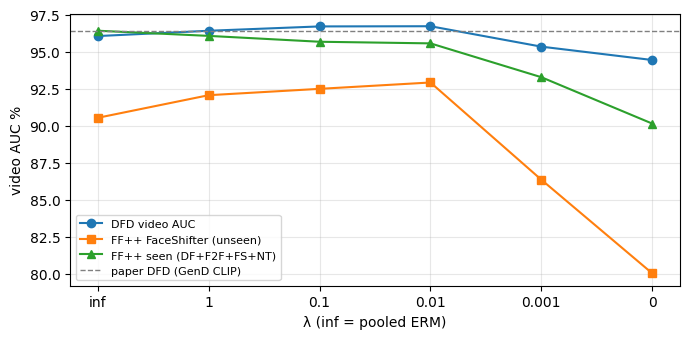

In [10]:
# 6. FF++ vs DFD per model
SEEN = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]


def ff_video_auc(pred, gens):
    sub = pred[pred.generator.isin(["original", *gens])]
    vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


cmp_rows = []
for k, (name, _, _, ref_path) in MODELS.items():
    row = {"model": name, "DFD video AUC": 100 * auc(y_vid, VIDEO_SCORES[k])}
    if ref_path is not None and ref_path.exists():
        pred = pd.read_csv(ref_path)
        pred = pred[pred.split == "test"] if "split" in pred else pred
        row["FF++ seen (DF+F2F+FS+NT)"] = ff_video_auc(pred, SEEN)
        row["FF++ NT"] = ff_video_auc(pred, ["NeuralTextures"])
        row["FF++ FaceShifter (unseen)"] = ff_video_auc(pred, ["FaceShifter"])
    elif k in FF_FSH_RECOMPUTED:
        row["FF++ FaceShifter (unseen)"] = FF_FSH_RECOMPUTED[k]
    cmp_rows.append(row)
ff_vs_dfd = pd.DataFrame(cmp_rows).set_index("model")
display(ff_vs_dfd.round(2))
ff_vs_dfd.to_csv(M8B_DIR / "ff_vs_dfd.csv")

lam_keys = [k for k in ["lam_inf", "lam_1", "lam_0.1", "lam_0.01", "lam_0.001", "lam_0"] if k in MODELS]
labels = [k.replace("lam_", "") for k in lam_keys]
fig, ax = plt.subplots(figsize=(7, 3.5))
for col, marker in [("DFD video AUC", "o"), ("FF++ FaceShifter (unseen)", "s"), ("FF++ seen (DF+F2F+FS+NT)", "^")]:
    if col in ff_vs_dfd:
        ax.plot(labels, [ff_vs_dfd.loc[MODELS[k][0], col] for k in lam_keys], marker=marker, label=col)
ax.axhline(PAPER_DFD_VIDEO_AUC, ls="--", c="gray", lw=1, label="paper DFD (GenD CLIP)")
ax.set_xlabel("λ (inf = pooled ERM)"); ax.set_ylabel("video AUC %"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M8B_DIR / "lambda_curve.png", dpi=150); plt.show()

## 7. Where the errors are

### 7.1 Per scene

Real vs fake videos of the same scene. Two-person scenes are where the crop may show the untouched person in a fake.

In [11]:
# 7.1 Per scene
multi = index.assign(multi=index.n_faces >= 2).groupby("scene").multi.mean() * 100
scene_rows = []
for scene, sub in videos.groupby("scene"):
    rows_ = sub.index.values
    row = {"scene": scene, "real": int((sub.label == 0).sum()), "fake": int((sub.label == 1).sum()),
           "frames ≥2 faces %": multi[scene]}
    for k in MAIN:
        row[MODELS[k][0]] = 100 * auc(y_vid[rows_], VIDEO_SCORES[k][rows_])
    scene_rows.append(row)
per_scene = pd.DataFrame(scene_rows).set_index("scene").sort_values("frames ≥2 faces %", ascending=False)
display(per_scene.round(2))
per_scene.to_csv(M8B_DIR / "dfd_per_scene.csv")

,real,fake,frames ≥2 faces %,LNCLIP-DF repro (M1),"pooled, λ=∞ (M4)",GBLA λ=0.01 (ours)
scene,,,,,,
walking_and_outside_surprised,15,124,100.00,78.23,85.00,88.33
walking_down_indoor_hall_disgust,15,106,99.69,85.03,88.11,89.06
meeting_serious,4,53,99.12,60.85,61.79,72.17
secret_conversation,18,164,58.46,86.55,88.35,89.33
talking_angry_couch,22,176,22.21,98.84,97.86,99.74
walking_outside_cafe_disgusted,26,213,18.37,98.14,97.85,98.95
walking_down_street_outside_angry,28,201,17.62,97.78,98.60,99.08
hugging_happy,16,164,11.61,99.54,98.82,99.77
kitchen_pan,27,236,11.18,99.67,99.67,99.98


### 7.2 Two-person sensitivity

Same models, three views of the data:

- **all videos** (paper protocol; the headline number)
- **without the 3 two-person scenes** (≈100% of frames have ≥2 faces)
- **single-face frames only**: each video scored on its frames with exactly one confident face (all frames if it has none)

If GBLA's ranking against the baselines is the same in all three, the two-person issue does not drive the comparison.

In [12]:
# 7.2 Sensitivity
keep_scene = ~videos.scene.isin(TWO_FACE_SCENES).values
single_mask = (index.n_faces == 1).values
print(f"videos without the two-person scenes: {keep_scene.sum()} "
      f"(real {(y_vid[keep_scene] == 0).sum()}, fake {(y_vid[keep_scene] == 1).sum()})")
print(f"single-face frames: {single_mask.mean() * 100:.1f}% of crops")

sens_rows, SENS_BOOT = [], {}
for k, (name, *_ ) in MODELS.items():
    s_single = video_scores(k, single_mask)
    SENS_BOOT[k] = boot_auc(VIDEO_SCORES[k], keep_scene)
    sens_rows.append({"model": name,
                      "all videos": 100 * auc(y_vid, VIDEO_SCORES[k]),
                      "without two-person scenes": 100 * auc(y_vid[keep_scene], VIDEO_SCORES[k][keep_scene]),
                      "single-face frames": 100 * auc(y_vid, s_single)})
sensitivity = pd.DataFrame(sens_rows).set_index("model")
display(sensitivity.round(2))
sensitivity.to_csv(M8B_DIR / "dfd_sensitivity.csv")

d = (SENS_BOOT[OURS] - SENS_BOOT["m1"]) * 100
print(f"without two-person scenes, ours − M1: {sensitivity.iloc[:, 1][MODELS[OURS][0]] - sensitivity.iloc[:, 1][MODELS['m1'][0]]:+.2f} "
      f"[{np.nanpercentile(d, 2.5):+.2f}, {np.nanpercentile(d, 97.5):+.2f}]")

videos without the two-person scenes: 3114 (real 329, fake 2785)
single-face frames: 80.1% of crops


,all videos,without two-person scenes,single-face frames
model,,,
LNCLIP-DF repro (M1),95.88,97.49,96.44
"pooled, λ=∞ (M4)",96.05,97.65,96.43
GBLA λ=1,96.40,98.08,96.85
GBLA λ=0.1,96.70,98.39,97.07
GBLA λ=0.01 (ours),96.71,98.35,97.07
GBLA λ=0.001,95.33,96.41,95.74
GBLA λ=0,94.43,95.45,94.74
uniform merge (M6),92.68,93.87,92.84
Fisher merge (M6),94.95,96.36,95.19


without two-person scenes, ours − M1: +0.87 [+0.38, +1.41]


## 8. ROC curves and summary

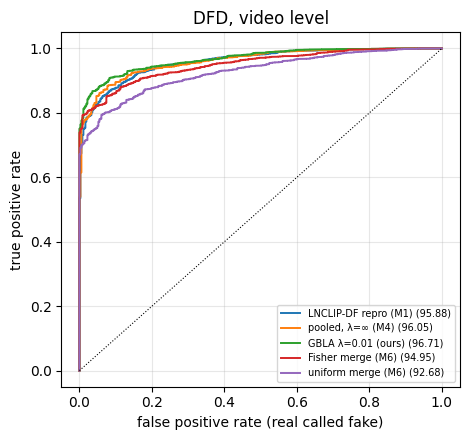

In [13]:
# 8.1 ROC curves (video level)
fig, ax = plt.subplots(figsize=(4.8, 4.5))
for k in MAIN + [k for k in ("fisher", "uniform") if k in MODELS]:
    fpr, tpr = roc_points(y_vid, VIDEO_SCORES[k])
    ax.plot(fpr, tpr, label=f"{MODELS[k][0]} ({100 * auc(y_vid, VIDEO_SCORES[k]):.2f})", lw=1.4)
ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set_xlabel("false positive rate (real called fake)"); ax.set_ylabel("true positive rate")
ax.set_title("DFD, video level"); ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M8B_DIR / "dfd_roc.png", dpi=150); plt.show()

In [14]:
# 8.2 Summary
summary = {
    "protocol": "train FF++ c23 (DF, F2F, FS, NT), test DFD 363 real + 3068 fake, video AUC = mean frame prob",
    "parameters": param_report,
    "paper_gend_clip_dfd_video_auc": PAPER_DFD_VIDEO_AUC,
    "load_check": load_check.astype(str).to_dict("records"),
    "dfd": main_table.drop(columns=["key"]).round(3).astype(str).to_dict("index"),
    "paired_differences_ours_minus": diffs.round(3).astype(str).to_dict("index"),
    "sensitivity": sensitivity.round(3).to_dict("index"),
    "bootstrap": f"{N_BOOT} actor-cluster resamples ({len(actors)} actors), seed {SEED}",
    "seeds_per_model": 1,
}
(M8B_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps({k: summary[k] for k in ("dfd", "paired_differences_ours_minus")}, indent=1, ensure_ascii=False))

{
 "dfd": {
  "LNCLIP-DF repro (M1)": {
   "video AUC": "95.884",
   "95% CI": "[94.33, 97.37]",
   "frame AUC": "91.443",
   "video AP": "99.495",
   "video EER": "11.335",
   "real acc": "85.95",
   "fake acc": "90.417"
  },
  "pooled, λ=∞ (M4)": {
   "video AUC": "96.046",
   "95% CI": "[94.38, 97.65]",
   "frame AUC": "92.227",
   "video AP": "99.518",
   "video EER": "10.449",
   "real acc": "83.196",
   "fake acc": "92.894"
  },
  "GBLA λ=1": {
   "video AUC": "96.403",
   "95% CI": "[94.85, 98.01]",
   "frame AUC": "92.932",
   "video AP": "99.569",
   "video EER": "9.929",
   "real acc": "85.399",
   "fake acc": "92.047"
  },
  "GBLA λ=0.1": {
   "video AUC": "96.696",
   "95% CI": "[95.20, 98.21]",
   "frame AUC": "93.123",
   "video AP": "99.606",
   "video EER": "9.645",
   "real acc": "90.634",
   "fake acc": "89.831"
  },
  "GBLA λ=0.01 (ours)": {
   "video AUC": "96.709",
   "95% CI": "[95.30, 98.21]",
   "frame AUC": "92.858",
   "video AP": "99.608",
   "video EER": "9.